# Audiencias Agencia Digital — Laboratorio Económico con linaje de proyecto

Notebook hermano de `12_marketing_audiences_economics_lab.ipynb`, enfocado en los medios de la agencia tercerizada.

El laboratorio distingue tres momentos del proyecto:

- **Proyecto origen**: proyecto por el que ingresó el lead (`raw_cygnus.clientes_proyectos`).
- **Proyecto proforma**: proyecto cotizado.
- **Proyecto conversión**: proyecto de separación/minuta/venta.
- **Proyecto analítico**: prioridad `ORIGEN > CONVERSION > PROFORMA > CLIENTE`.

También conserva el linaje multi-proyecto en `analytics.marketing_audiencias_proyectos`.

> Las hojas internas sirven para análisis. Las hojas exportables siguen exigiendo `apto_entrega_externa = TRUE`.


## 1. Parámetros del análisis

`FECHA_INICIO` y `FECHA_CORTE` son opcionales y filtran por la fecha de origen del lead (`fecha_origen_primario`, con fallback a `fecha_cliente`).

Formatos aceptados: `DD/MM/YY`, `DD/MM/YYYY` o `YYYY-MM-DD`.

Usar `None` para dejar un límite abierto.


In [1]:
from pathlib import Path
from datetime import datetime
import re
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# PARÁMETROS EDITABLES
# ------------------------------------------------------------
FECHA_INICIO = "01/07/26"   # None = sin límite inferior
FECHA_CORTE = "15/10/26"    # None = sin límite superior


def parse_fecha(value):
    if value is None or str(value).strip() == "":
        return None

    value = str(value).strip()
    for fmt in ("%d/%m/%y", "%d/%m/%Y", "%Y-%m-%d"):
        try:
            return datetime.strptime(value, fmt).date()
        except ValueError:
            pass

    raise ValueError(
        f"Fecha inválida: {value!r}. Use DD/MM/YY, DD/MM/YYYY, YYYY-MM-DD o None."
    )


fecha_inicio = parse_fecha(FECHA_INICIO)
fecha_corte = parse_fecha(FECHA_CORTE)

if fecha_inicio and fecha_corte and fecha_inicio > fecha_corte:
    raise ValueError("FECHA_INICIO no puede ser posterior a FECHA_CORTE.")


def root(start):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src").exists():
            return candidate
    raise RuntimeError("Abra el notebook dentro de bd_replica_crm.")


ROOT = root(Path.cwd().resolve())

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from replica_cygnus.connections import connect_postgres
from replica_cygnus.settings import load_settings

cfg = yaml.safe_load(
    (ROOT / "config" / "marketing_agency_channels.yml").read_text(encoding="utf-8")
)

norm = lambda x: re.sub(r"\s+", " ", str(x or "").strip().lower())

alias = {
    norm(value): channel["label"]
    for channel in cfg["channels"]
    for value in channel["match_values"]
}

MEDIA = sorted(alias)
LABELS = [channel["label"] for channel in cfg["channels"]]


def q(sql, params=None):
    with connect_postgres(load_settings(require_source=False)) as cn:
        with cn.transaction(), cn.cursor() as cur:
            cur.execute("SET TRANSACTION READ ONLY")
            cur.execute(sql, params)
            return pd.DataFrame(
                cur.fetchall(),
                columns=[column.name for column in cur.description],
            )


PERIODO = (
    f"{fecha_inicio or 'inicio abierto'} → {fecha_corte or 'corte abierto'}"
)

print(f"Periodo del análisis: {PERIODO}")
print(f"Medios agencia: {', '.join(LABELS)}")


Periodo del análisis: 2026-07-01 → 2026-10-15
Medios agencia: Facebook, Tik Tok, Instagram, Meta, Google


## 2. Extracción analítica sin PII

El filtro temporal se aplica a la fecha en que la persona entra al universo de captación.  
Esto hace que las cohortes, tasas y bases operativas trabajen sobre el mismo intervalo.


In [2]:
SQL = """
SELECT
    COALESCE(NULLIF(proyecto_origen, ''), NULLIF(proyecto, ''), 'Sin proyecto')
        AS proyecto_origen_analitico,
    proyecto_origen,
    proyecto_proforma,
    proyecto_conversion,
    proyecto,
    fuente_proyecto,
    cambio_proyecto::int AS cambio_proyecto,

    codigo_proyecto_origen,
    codigo_proyecto_proforma,
    codigo_proyecto_conversion,

    regexp_replace(
        lower(trim(COALESCE(medio_captacion, ''))),
        '\\s+', ' ', 'g'
    ) AS medio,

    fecha_cliente,
    fecha_cliente_crm,
    fecha_origen_primario,

    etapa_maxima,
    positiva::int AS positiva,
    negativa_sin_avance::int AS negativa_sin_avance,

    contacto_valido::int AS contacto_valido,
    exclusion_no_contactar::int AS exclusion_no_contactar,
    consentimiento_publicidad_verificado::int AS consentimiento_verificado,
    apto_entrega_externa::int AS apto_entrega_externa

FROM analytics.marketing_audiencias

WHERE regexp_replace(
        lower(trim(COALESCE(medio_captacion, ''))),
        '\\s+', ' ', 'g'
      ) = ANY(%(media)s)

  AND (
        %(fecha_inicio)s::date IS NULL
        OR COALESCE(fecha_origen_primario, fecha_cliente) >= %(fecha_inicio)s::date
      )

  AND (
        %(fecha_corte)s::date IS NULL
        OR COALESCE(fecha_origen_primario, fecha_cliente) <= %(fecha_corte)s::date
      )
"""

PARAMS = {
    "media": MEDIA,
    "fecha_inicio": fecha_inicio,
    "fecha_corte": fecha_corte,
}

aud = q(SQL, PARAMS)

aud["canal"] = aud["medio"].map(alias)

for col in ["fecha_cliente", "fecha_cliente_crm", "fecha_origen_primario"]:
    aud[col] = pd.to_datetime(aud[col], errors="coerce")

aud["negativa_activable"] = (
    (aud["negativa_sin_avance"] == 1)
    & (aud["apto_entrega_externa"] == 1)
).astype(int)

aud["negativa_interna"] = (
    (aud["negativa_sin_avance"] == 1)
    & (aud["contacto_valido"] == 1)
    & (aud["exclusion_no_contactar"] == 0)
).astype(int)

if aud.empty:
    raise RuntimeError(
        "El filtro no devolvió audiencias. Revise fechas, medios o ejecute "
        "refresh_marketing_audiences.py."
    )

if aud["canal"].isna().any():
    raise RuntimeError("Hay medios de agencia sin alias configurado.")

print(
    f"Personas agencia: {len(aud):,} | "
    f"con proyecto origen: {aud.proyecto_origen.notna().sum():,} | "
    f"cambios de proyecto: {aud.cambio_proyecto.sum():,} | "
    f"PII en análisis: NO"
)


Personas agencia: 5,287 | con proyecto origen: 5,286 | cambios de proyecto: 63 | PII en análisis: NO


## 3. Estadística, concentración e incertidumbre

Separa volumen de tasa positiva. El HHI resume concentración por medio y Wilson 95% evita leer diferencias puntuales como certezas.


,canal,personas,positivas,tasa_positiva,negativas_rmkt,negativas_internas,negativas_activables,contactabilidad,aptitud_externa,cobertura_proyecto_origen,cambios_proyecto,participacion,ci95_low,ci95_high,brecha_pp
0,Facebook,5255,151,0.028735,0,0,0,1.0,0.0,0.99981,60,0.993947,0.024551,0.033607,-0.115008
1,Tik Tok,17,2,0.117647,0,0,0,1.0,0.0,1.00000,0,0.003215,0.032880,0.343364,8.776244
2,Instagram,9,1,0.111111,0,0,0,1.0,0.0,1.00000,0,0.001702,0.019891,0.435000,8.122649
3,Meta,5,4,0.800000,0,0,0,1.0,0.0,1.00000,3,0.000946,0.375535,0.963776,77.011538
4,Google,1,0,0.000000,0,0,0,1.0,0.0,1.00000,0,0.000189,0.000000,0.793451,-2.988462


Tasa agencia=2.99% | HHI=0.988 | Cobertura proyecto origen=99.98%


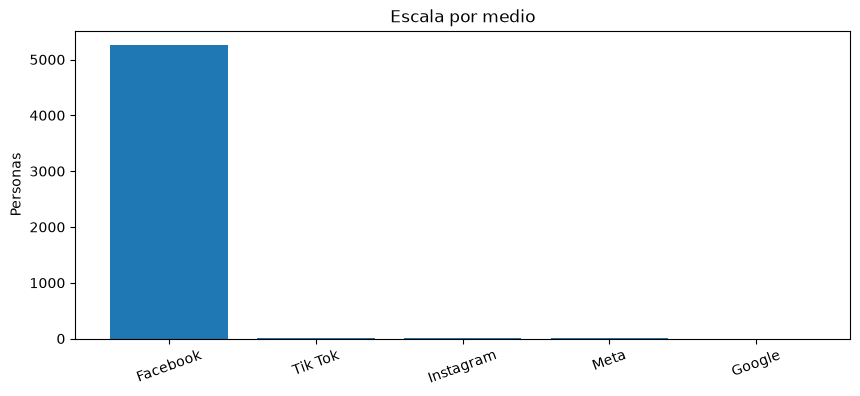

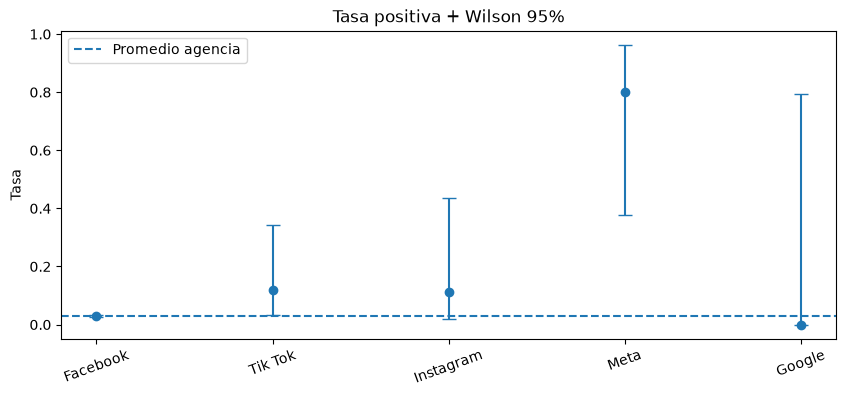

In [3]:
ch = (
    aud.groupby("canal")
    .agg(
        personas=("positiva", "size"),
        positivas=("positiva", "sum"),
        tasa_positiva=("positiva", "mean"),
        negativas_rmkt=("negativa_sin_avance", "sum"),
        negativas_internas=("negativa_interna", "sum"),
        negativas_activables=("negativa_activable", "sum"),
        contactabilidad=("contacto_valido", "mean"),
        aptitud_externa=("apto_entrega_externa", "mean"),
        cobertura_proyecto_origen=("proyecto_origen", lambda s: s.notna().mean()),
        cambios_proyecto=("cambio_proyecto", "sum"),
    )
    .sort_values("personas", ascending=False)
)

ch["participacion"] = ch["personas"] / ch["personas"].sum()
hhi = float((ch["participacion"] ** 2).sum())

ci = ch.apply(
    lambda r: proportion_confint(
        int(r["positivas"]),
        int(r["personas"]),
        method="wilson",
    ),
    axis=1,
)

ch["ci95_low"] = [x[0] for x in ci]
ch["ci95_high"] = [x[1] for x in ci]

portfolio = float(aud["positiva"].mean())
ch["brecha_pp"] = (ch["tasa_positiva"] - portfolio) * 100

display(ch.reset_index())

print(
    f"Tasa agencia={portfolio:.2%} | "
    f"HHI={hhi:.3f} | "
    f"Cobertura proyecto origen={aud.proyecto_origen.notna().mean():.2%}"
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(ch.index, ch["personas"])
ax.set(title="Escala por medio", ylabel="Personas")
plt.xticks(rotation=20)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ch))
y = ch["tasa_positiva"].to_numpy()

ax.errorbar(
    x,
    y,
    yerr=np.vstack(
        [
            y - ch["ci95_low"].to_numpy(),
            ch["ci95_high"].to_numpy() - y,
        ]
    ),
    fmt="o",
    capsize=5,
)

ax.axhline(portfolio, ls="--", label="Promedio agencia")
ax.set_xticks(x, ch.index, rotation=20)
ax.set(title="Tasa positiva + Wilson 95%", ylabel="Tasa")
ax.legend()
plt.show()


## 4. Hipótesis y matriz proyecto origen × medio

**H0:** la tasa positiva es independiente del medio.

Se usa χ² global y comparaciones de proporciones contra el canal de mayor volumen con ajuste de Holm. Esto detecta asociación, no causalidad.


Chi²=109.12 | p=1.121e-22 | gl=4


,benchmark,challenger,diferencia_pp,z,p_value,p_holm
0,Facebook,Tik Tok,8.891252,2.180335,2.923266e-02,8.769799e-02
1,Facebook,Instagram,8.237657,1.474525,1.403404e-01,2.806807e-01
2,Facebook,Meta,77.126546,10.193056,2.129631e-24,8.518526e-24
3,Facebook,Google,-2.873454,-0.172001,8.634364e-01,8.634364e-01


canal,Facebook,Tik Tok,Instagram,Meta,Google
proyecto_origen_analitico,,,,,
Alicanto,0.106557,0.000000,NaN,1.000000,NaN
Campañas,0.166667,NaN,NaN,0.666667,0.0
Capadocia,0.020387,0.000000,0.0,1.000000,NaN
Edificio Urbanzen,0.083832,NaN,0.0,NaN,NaN
Edificio Valdizan,0.000000,NaN,NaN,NaN,NaN
Fenix,0.052910,NaN,0.0,NaN,NaN
Matera,0.020080,NaN,NaN,NaN,NaN
Modena,0.041162,0.000000,NaN,NaN,NaN
Sialia,0.044563,NaN,0.0,NaN,NaN


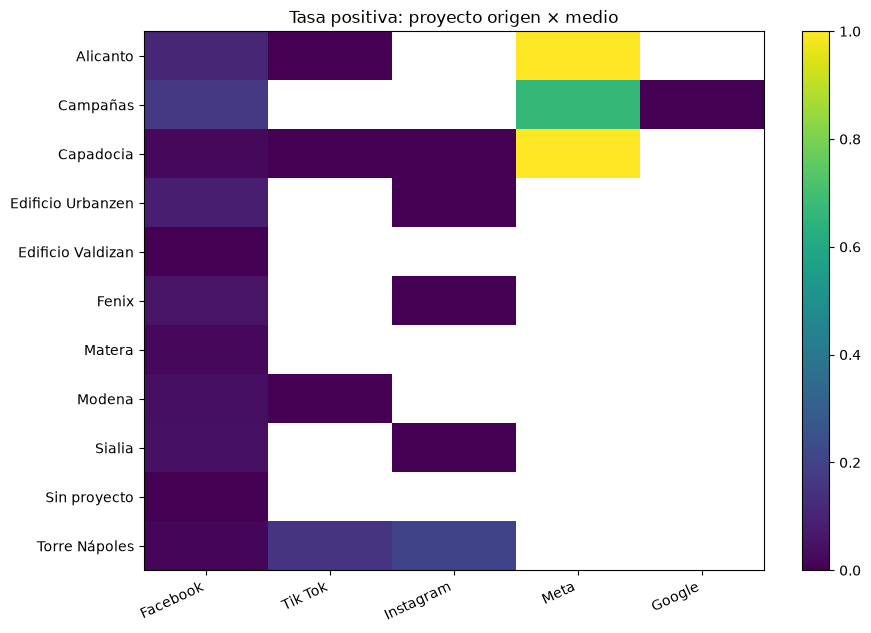

In [4]:
ct = pd.crosstab(aud["canal"], aud["positiva"]).reindex(columns=[0, 1], fill_value=0)

pair = pd.DataFrame(
    columns=["benchmark", "challenger", "diferencia_pp", "z", "p_value", "p_holm"]
)

if len(ct) >= 2 and (ct.sum(axis=0) > 0).all():
    chi2, p_global, dof, _ = chi2_contingency(ct)

    benchmark = ch.index[0]
    tests = []

    for channel in ch.index[1:]:
        z, p = proportions_ztest(
            [
                int(ch.loc[channel, "positivas"]),
                int(ch.loc[benchmark, "positivas"]),
            ],
            [
                int(ch.loc[channel, "personas"]),
                int(ch.loc[benchmark, "personas"]),
            ],
        )

        tests.append(
            [
                benchmark,
                channel,
                (
                    ch.loc[channel, "tasa_positiva"]
                    - ch.loc[benchmark, "tasa_positiva"]
                )
                * 100,
                z,
                p,
            ]
        )

    pair = pd.DataFrame(
        tests,
        columns=[
            "benchmark",
            "challenger",
            "diferencia_pp",
            "z",
            "p_value",
        ],
    )

    if len(pair):
        pair["p_holm"] = multipletests(
            pair["p_value"],
            method="holm",
        )[1]

    print(f"Chi²={chi2:.2f} | p={p_global:.4g} | gl={dof}")

else:
    chi2 = p_global = dof = np.nan
    print("No hay suficiente variación para χ² en el periodo elegido.")

display(pair)

pc = (
    aud.groupby(["proyecto_origen_analitico", "canal"])
    .agg(
        personas=("positiva", "size"),
        positivas=("positiva", "sum"),
        tasa=("positiva", "mean"),
        negativas_internas=("negativa_interna", "sum"),
        negativas_activables=("negativa_activable", "sum"),
    )
    .reset_index()
)

top_projects = (
    pc.groupby("proyecto_origen_analitico")["personas"]
    .sum()
    .nlargest(15)
    .index
)

matrix_project = (
    pc[pc["proyecto_origen_analitico"].isin(top_projects)]
    .pivot(
        index="proyecto_origen_analitico",
        columns="canal",
        values="tasa",
    )
    .reindex(columns=LABELS)
)

display(matrix_project)

if len(matrix_project):
    data = matrix_project.to_numpy(float)
    vmax = max(0.05, float(np.nanmax(data)) if np.isfinite(data).any() else 0.05)

    fig, ax = plt.subplots(figsize=(10, 7))
    image = ax.imshow(
        data,
        aspect="auto",
        vmin=0,
        vmax=vmax,
    )
    ax.set_xticks(
        range(len(matrix_project.columns)),
        matrix_project.columns,
        rotation=25,
        ha="right",
    )
    ax.set_yticks(
        range(len(matrix_project.index)),
        matrix_project.index,
    )
    ax.set_title("Tasa positiva: proyecto origen × medio")
    fig.colorbar(image, ax=ax)
    plt.show()


## 5. Cohortes

La cohorte se define por la fecha de origen del lead. Esto reduce la distorsión de comparar leads recientes con leads que tuvieron mucho más tiempo para avanzar.


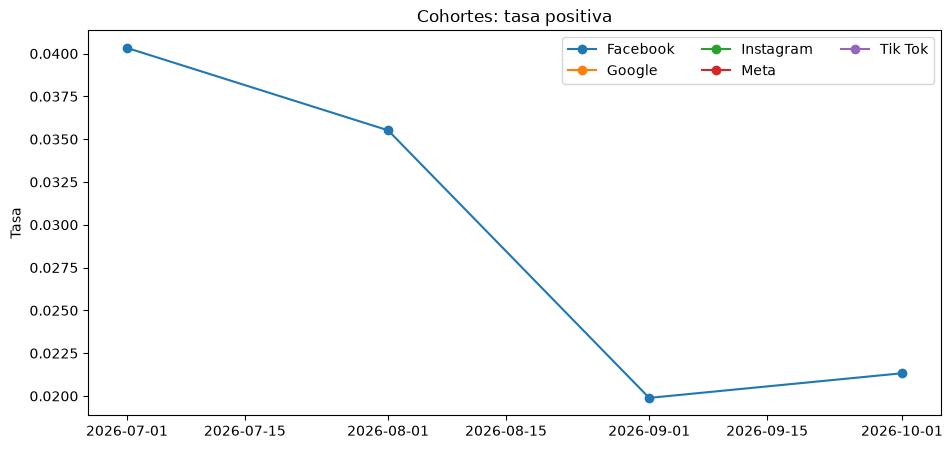

,cohorte,canal,personas,tasa_positiva,negativas_internas,negativas_activables
0,2026-07-01,Facebook,967,0.040331,0,0
1,2026-07-01,Instagram,1,0.000000,0,0
2,2026-07-01,Meta,1,1.000000,0,0
3,2026-07-01,Tik Tok,1,0.000000,0,0
4,2026-08-01,Facebook,1633,0.035517,0,0
5,2026-08-01,Instagram,2,0.000000,0,0
6,2026-08-01,Meta,2,0.500000,0,0
7,2026-09-01,Facebook,1810,0.019890,0,0
8,2026-09-01,Google,1,0.000000,0,0
9,2026-09-01,Instagram,6,0.166667,0,0


In [5]:
co = aud.dropna(subset=["fecha_origen_primario"]).copy()

if co.empty:
    co = aud.dropna(subset=["fecha_cliente"]).copy()
    co["fecha_cohorte"] = co["fecha_cliente"]
else:
    co["fecha_cohorte"] = co["fecha_origen_primario"]

co["cohorte"] = co["fecha_cohorte"].dt.to_period("M").dt.to_timestamp()

coh = (
    co.groupby(["cohorte", "canal"])
    .agg(
        personas=("positiva", "size"),
        tasa_positiva=("positiva", "mean"),
        negativas_internas=("negativa_interna", "sum"),
        negativas_activables=("negativa_activable", "sum"),
    )
    .reset_index()
)

if not coh.empty:
    recent = coh[
        coh["cohorte"]
        >= coh["cohorte"].max() - pd.DateOffset(months=23)
    ].copy()

    recent.loc[
        recent["personas"] < 40,
        "tasa_positiva",
    ] = np.nan

    fig, ax = plt.subplots(figsize=(11, 5))

    for channel, data in recent.groupby("canal"):
        ax.plot(
            data["cohorte"],
            data["tasa_positiva"],
            marker="o",
            label=channel,
        )

    ax.set(
        title="Cohortes: tasa positiva",
        ylabel="Tasa",
    )
    ax.legend(ncol=3)
    plt.show()

display(coh.tail(40))


## 6. Migración entre proyectos: origen → proforma → conversión

Esta sección separa adquisición de cierre.

Permite responder:

- ¿Qué proyecto captó originalmente al lead?
- ¿En qué proyecto proformó?
- ¿En cuál terminó separando/minutando/vendiendo?
- ¿Qué pares de proyectos presentan mayor sustitución o cross-selling?


In [6]:
flow_conversion = (
    aud.dropna(subset=["proyecto_origen", "proyecto_conversion"])
    .groupby(["proyecto_origen", "proyecto_conversion"])
    .agg(
        personas=("positiva", "size"),
        positivas=("positiva", "sum"),
    )
    .reset_index()
)

if not flow_conversion.empty:
    flow_conversion["participacion_dentro_origen"] = (
        flow_conversion["personas"]
        / flow_conversion.groupby("proyecto_origen")["personas"].transform("sum")
    )

flow_path = (
    aud.groupby(
        [
            "proyecto_origen_analitico",
            "proyecto_proforma",
            "proyecto_conversion",
            "cambio_proyecto",
        ],
        dropna=False,
    )
    .agg(
        personas=("positiva", "size"),
        positivas=("positiva", "sum"),
    )
    .reset_index()
    .sort_values("personas", ascending=False)
)

display(flow_conversion.sort_values("personas", ascending=False).head(30))
display(flow_path.head(30))


,proyecto_origen,proyecto_conversion,personas,positivas,participacion_dentro_origen
1,Alicanto,Capadocia,2,2,0.50
0,Alicanto,Alicanto,1,1,0.25
2,Alicanto,Sialia,1,1,0.25
3,Edificio Urbanzen,Modena,1,1,1.00
4,Torre Nápoles,Torre Nápoles,1,1,1.00


,proyecto_origen_analitico,proyecto_proforma,proyecto_conversion,cambio_proyecto,personas,positivas
21,Capadocia,NaN,NaN,0,1877,0
66,Torre Nápoles,NaN,NaN,0,1372,0
56,Sialia,NaN,NaN,0,537,0
39,Matera,NaN,NaN,0,488,0
47,Modena,NaN,NaN,0,397,0
35,Fenix,NaN,NaN,0,180,0
29,Edificio Urbanzen,NaN,NaN,0,154,0
9,Alicanto,NaN,NaN,0,110,0
14,Capadocia,Capadocia,NaN,0,24,24
53,Sialia,Sialia,NaN,0,17,17


## 7. Linaje multi-proyecto

`analytics.marketing_audiencias_proyectos` conserva una fila por persona × proyecto.  
Aquí se usa solo en forma agregada, sin PII.


In [7]:
PROJECT_SQL = """
SELECT
    mp.codigo_proyecto,
    mp.proyecto,

    count(*)::bigint AS relaciones_persona_proyecto,
    count(*) FILTER (WHERE mp.es_primer_touch)::bigint AS personas_primer_touch,

    sum(mp.cantidad_leads)::bigint AS leads_registrados,

    count(*) FILTER (WHERE mp.tuvo_proforma)::bigint AS personas_con_proforma,
    count(*) FILTER (WHERE mp.tuvo_separacion)::bigint AS personas_con_separacion,
    count(*) FILTER (WHERE mp.tuvo_minuta_venta)::bigint AS personas_con_minuta_venta

FROM analytics.marketing_audiencias_proyectos mp

JOIN analytics.marketing_audiencias ma
  USING (persona_key)

WHERE regexp_replace(
        lower(trim(COALESCE(ma.medio_captacion, ''))),
        '\\s+', ' ', 'g'
      ) = ANY(%(media)s)

  AND (
        %(fecha_inicio)s::date IS NULL
        OR COALESCE(ma.fecha_origen_primario, ma.fecha_cliente)
            >= %(fecha_inicio)s::date
      )

  AND (
        %(fecha_corte)s::date IS NULL
        OR COALESCE(ma.fecha_origen_primario, ma.fecha_cliente)
            <= %(fecha_corte)s::date
      )

GROUP BY
    mp.codigo_proyecto,
    mp.proyecto

ORDER BY
    relaciones_persona_proyecto DESC,
    mp.proyecto
"""

project_detail = q(PROJECT_SQL, PARAMS)

display(project_detail.head(30))


,codigo_proyecto,proyecto,relaciones_persona_proyecto,personas_primer_touch,leads_registrados,personas_con_proforma,personas_con_separacion,personas_con_minuta_venta
0,CP,Capadocia,2056,1917,2056,45,2,2
1,NP,Torre Nápoles,1558,1429,1558,31,1,0
2,SL,Sialia,688,591,688,25,1,1
3,MT,Matera,630,522,630,19,0,0
4,MD,Modena,488,425,488,17,1,1
5,FX,Fenix,264,201,264,16,0,0
6,GY,Alicanto,209,139,209,20,1,1
7,EEUU,Edificio Urbanzen,196,173,196,13,0,0
8,CAM,Campañas,23,16,23,0,0,0
9,TZ,Tizón y Bueno,11,5,11,7,0,0


## 8. Excel ejecutivo + bases internas y exportables

El Excel separa explícitamente:

- **10/11/12**: bases internas reales para análisis y operación interna.
- **20/21**: bases entregables a terceros; exigen `apto_entrega_externa = TRUE`.

Las bases internas no se muestran en pantalla dentro del notebook.


In [8]:
COMMON_WHERE = """
WHERE regexp_replace(
        lower(trim(COALESCE(medio_captacion, ''))),
        '\\s+', ' ', 'g'
      ) = ANY(%(media)s)

  AND (
        %(fecha_inicio)s::date IS NULL
        OR COALESCE(fecha_origen_primario, fecha_cliente)
            >= %(fecha_inicio)s::date
      )

  AND (
        %(fecha_corte)s::date IS NULL
        OR COALESCE(fecha_origen_primario, fecha_cliente)
            <= %(fecha_corte)s::date
      )
"""


POS = """
SELECT
    "Nombres" AS nombres,
    "Apellidos" AS apellidos,
    "Telefono_Celular" AS telefono_celular,
    "Correo_electronico" AS correo_electronico,

    medio_captacion,

    codigo_proyecto_origen,
    proyecto_origen,

    codigo_proyecto_proforma,
    proyecto_proforma,

    codigo_proyecto_conversion,
    proyecto_conversion,

    proyecto,
    fuente_proyecto,
    cambio_proyecto,

    fecha_origen_primario,
    fecha_cliente,

    etapa_maxima,

    fecha_ultimo_avance AT TIME ZONE 'America/Lima'
        AS fecha_ultimo_avance,

    consentimiento_publicidad_verificado,
    apto_entrega_externa

FROM analytics.v_marketing_positiva
""" + COMMON_WHERE


NEG = """
SELECT
    "Nombres" AS nombres,
    "Apellidos" AS apellidos,
    "Telefono_Celular" AS telefono_celular,
    "Correo_electronico" AS correo_electronico,

    medio_captacion,

    codigo_proyecto_origen,
    proyecto_origen,

    codigo_proyecto_proforma,
    proyecto_proforma,

    codigo_proyecto_conversion,
    proyecto_conversion,

    proyecto,
    fuente_proyecto,
    cambio_proyecto,

    fecha_origen_primario,
    fecha_cliente,

    etapa_maxima,

    consentimiento_publicidad_verificado,
    apto_entrega_externa

FROM analytics.v_marketing_negativa_sin_avance
""" + COMMON_WHERE


NEUTRAL = """
SELECT
    "Nombres" AS nombres,
    "Apellidos" AS apellidos,
    "Telefono_Celular" AS telefono_celular,
    "Correo_electronico" AS correo_electronico,

    medio_captacion,

    codigo_proyecto_origen,
    proyecto_origen,

    codigo_proyecto_proforma,
    proyecto_proforma,

    codigo_proyecto_conversion,
    proyecto_conversion,

    proyecto,
    fuente_proyecto,
    cambio_proyecto,

    fecha_origen_primario,
    fecha_cliente,

    etapa_maxima,

    consentimiento_publicidad_verificado,
    apto_entrega_externa

FROM analytics.v_marketing_neutral_reciente
""" + COMMON_WHERE


base_pos = q(POS, PARAMS)
base_neg = q(NEG, PARAMS)
base_neutral = q(NEUTRAL, PARAMS)

base_pos_ext = base_pos[
    base_pos["apto_entrega_externa"].fillna(False).astype(bool)
].copy()

base_neg_ext = base_neg[
    base_neg["apto_entrega_externa"].fillna(False).astype(bool)
].copy()


def excel_safe(df):
    result = df.copy()

    for col in result.columns:
        series = result[col]

        if isinstance(series.dtype, pd.DatetimeTZDtype):
            result[col] = (
                series.dt.tz_convert("America/Lima")
                .dt.tz_localize(None)
            )

        elif pd.api.types.is_object_dtype(series):
            def strip_tz(value):
                if (
                    isinstance(value, (pd.Timestamp, datetime))
                    and getattr(value, "tzinfo", None) is not None
                ):
                    ts = pd.Timestamp(value)
                    return ts.tz_convert("America/Lima").tz_localize(None)
                return value

            result[col] = series.map(strip_tz)

    return result


out = ROOT / "outputs" / "marketing_agency_audiences"
out.mkdir(parents=True, exist_ok=True)

start_tag = fecha_inicio.strftime("%Y%m%d") if fecha_inicio else "inicio"
end_tag = fecha_corte.strftime("%Y%m%d") if fecha_corte else "corte"

path = out / (
    f"audiencias_agencia_{start_tag}_{end_tag}_"
    f"{datetime.now():%Y%m%d_%H%M%S}.xlsx"
)


def sheet(writer, name, df, title):
    df = excel_safe(df)

    df.to_excel(
        writer,
        sheet_name=name,
        startrow=3,
        index=False,
    )

    wb = writer.book
    ws = writer.sheets[name]

    ws.hide_gridlines(2)
    ws.freeze_panes(4, 0)

    title_fmt = wb.add_format(
        {
            "bold": True,
            "font_size": 16,
            "font_color": "#FFFFFF",
            "bg_color": "#172554",
        }
    )

    ws.merge_range(
        0,
        0,
        0,
        max(5, len(df.columns) - 1),
        title,
        title_fmt,
    )

    ws.set_row(0, 26)

    if len(df.columns):
        ws.autofilter(
            3,
            0,
            3 + len(df),
            len(df.columns) - 1,
        )

    pct_fmt = wb.add_format({"num_format": "0.0%"})

    for i, col in enumerate(df.columns):
        col_name = str(col).lower()

        cell_fmt = (
            pct_fmt
            if any(
                token in col_name
                for token in [
                    "tasa",
                    "participacion",
                    "aptitud",
                    "contactabilidad",
                    "cobertura",
                    "ci95",
                ]
            )
            else None
        )

        width = min(34, max(12, len(str(col)) + 2))
        ws.set_column(i, i, width, cell_fmt)


with pd.ExcelWriter(
    path,
    engine="xlsxwriter",
    datetime_format="yyyy-mm-dd hh:mm:ss",
) as w:

    wb = w.book

    ws = wb.add_worksheet("00_Resumen")
    w.sheets["00_Resumen"] = ws

    ws.hide_gridlines(2)
    ws.set_column("B:G", 22)

    title_fmt = wb.add_format(
        {
            "bold": True,
            "font_size": 20,
            "font_color": "#FFFFFF",
            "bg_color": "#172554",
        }
    )

    ws.merge_range(
        "B2:G3",
        "Audiencias Agencia Digital | Resumen",
        title_fmt,
    )

    kpi_fmt = wb.add_format(
        {
            "bold": True,
            "font_size": 15,
            "bg_color": "#EFF6FF",
            "border": 1,
        }
    )

    label_fmt = wb.add_format(
        {
            "font_color": "#475569",
        }
    )

    labels = [
        ("B6", "Personas agencia", len(aud)),
        ("D6", "Tasa positiva", portfolio),
        ("F6", "HHI", hhi),

        ("B9", "Positivas internas", len(base_pos)),
        ("D9", "Negativas RMKT internas", len(base_neg)),
        ("F9", "Neutrales recientes", len(base_neutral)),

        ("B12", "Positivas exportables", len(base_pos_ext)),
        ("D12", "Negativas exportables", len(base_neg_ext)),
        ("F12", "Aptitud externa", aud["apto_entrega_externa"].mean()),

        ("B15", "Cobertura proyecto origen", aud["proyecto_origen"].notna().mean()),
        ("D15", "Cambios de proyecto", int(aud["cambio_proyecto"].sum())),
        ("F15", "Relaciones persona-proyecto", int(project_detail["relaciones_persona_proyecto"].sum()) if len(project_detail) else 0),
    ]

    for cell, label, value in labels:
        ws.write(cell, value, kpi_fmt)
        ws.write(
            f"{cell[0]}{int(cell[1:]) + 1}",
            label,
            label_fmt,
        )

    ws.write("B19", "Periodo", label_fmt)
    ws.write("C19", PERIODO)
    ws.write("B20", "Base temporal", label_fmt)
    ws.write("C20", "fecha_origen_primario; fallback fecha_cliente")

    sheet(
        w,
        "01_Canales",
        ch.reset_index(),
        "Canales — escala, calidad e incertidumbre",
    )

    sheet(
        w,
        "02_Proyecto_Origen",
        pc,
        "Proyecto origen × canal",
    )

    sheet(
        w,
        "03_Cohortes",
        coh,
        "Cohortes de captación",
    )

    sheet(
        w,
        "04_Hipotesis",
        pair,
        "Hipótesis vs benchmark",
    )

    sheet(
        w,
        "05_Origen_Conversion",
        flow_conversion.sort_values("personas", ascending=False)
        if len(flow_conversion)
        else flow_conversion,
        "Flujo proyecto origen → proyecto conversión",
    )

    sheet(
        w,
        "06_Flujo_Proyectos",
        flow_path,
        "Ruta proyecto origen → proforma → conversión",
    )

    sheet(
        w,
        "07_Proyecto_Detalle",
        project_detail,
        "Linaje multi-proyecto agregado",
    )

    sheet(
        w,
        "10_Positiva_Interna",
        base_pos,
        "Base positiva interna",
    )

    sheet(
        w,
        "11_Negativa_RMKT_Interna",
        base_neg,
        "Base negativa RMKT interna",
    )

    sheet(
        w,
        "12_Neutral_Reciente",
        base_neutral,
        "Base neutral reciente interna",
    )

    sheet(
        w,
        "20_Positiva_Exportable",
        base_pos_ext,
        "Base positiva exportable",
    )

    sheet(
        w,
        "21_Negativa_Exportable",
        base_neg_ext,
        "Base negativa exportable",
    )


print(
    f"Excel generado: {path} | "
    f"periodo={PERIODO} | "
    f"positivas internas={len(base_pos):,} | "
    f"negativas internas={len(base_neg):,} | "
    f"neutrales={len(base_neutral):,} | "
    f"positivas exportables={len(base_pos_ext):,} | "
    f"negativas exportables={len(base_neg_ext):,}"
)


Excel generado: C:\Cygnus\projects\medallio_dw\outputs\marketing_agency_audiences\audiencias_agencia_20260701_20261015_20261015_162109.xlsx | periodo=2026-07-01 → 2026-10-15 | positivas internas=158 | negativas internas=0 | neutrales=5,129 | positivas exportables=0 | negativas exportables=0


## 9. Lectura final

- **Proyecto origen** gobierna el análisis de captación.
- **Proyecto proforma** y **proyecto conversión** permiten medir migración entre proyectos.
- `cambio_proyecto = TRUE` señala sustitución/cross-selling potencial.
- Las diferencias históricas son asociación; para medir lift incremental se necesita grupo control o un diseño causal defendible.
- No entregar a terceros filas con `apto_entrega_externa = FALSE`.
